Import libraries

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import matplotlib.pyplot as plt

Check working directory

In [2]:
import os

print(os.getcwd())

d:\Study\2nd sem1\ML practicles\experiments


Load dataset

In [3]:
df = pd.read_csv("../datasets/house_price_dataset.csv")

X = df[['Area_sqft', 'Bedrooms', 'Bathrooms', 'Year_Built']]

median_price = df['Price'].median()

y = (df['Price'] >= median_price).astype(int)

Split dataset

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Create Decision Tree model

In [4]:
model = make_pipeline(
    SimpleImputer(strategy='median'),
    DecisionTreeClassifier(
        criterion='gini',
        max_depth=4,
        random_state=42
    )
)

Train the model

In [5]:
model.fit(X_train, y_train)

Pipeline(steps=[('simpleimputer', SimpleImputer(strategy='median')),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=4, random_state=42))])

Make predictions

In [6]:
y_pred = model.predict(X_test)

print("Predictions:", y_pred)

Predictions: [0 0 0 ... 0 0 1]


Evaluate the model

In [7]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7876871880199667
Confusion Matrix:
[[1217  285]
 [ 353 1150]]
Classification Report:
              precision    recall  f1-score   support

           0       0.78      0.81      0.79      1502
           1       0.80      0.77      0.78      1503

    accuracy                           0.79      3005
   macro avg       0.79      0.79      0.79      3005
weighted avg       0.79      0.79      0.79      3005



 Visualize the Decision Tree

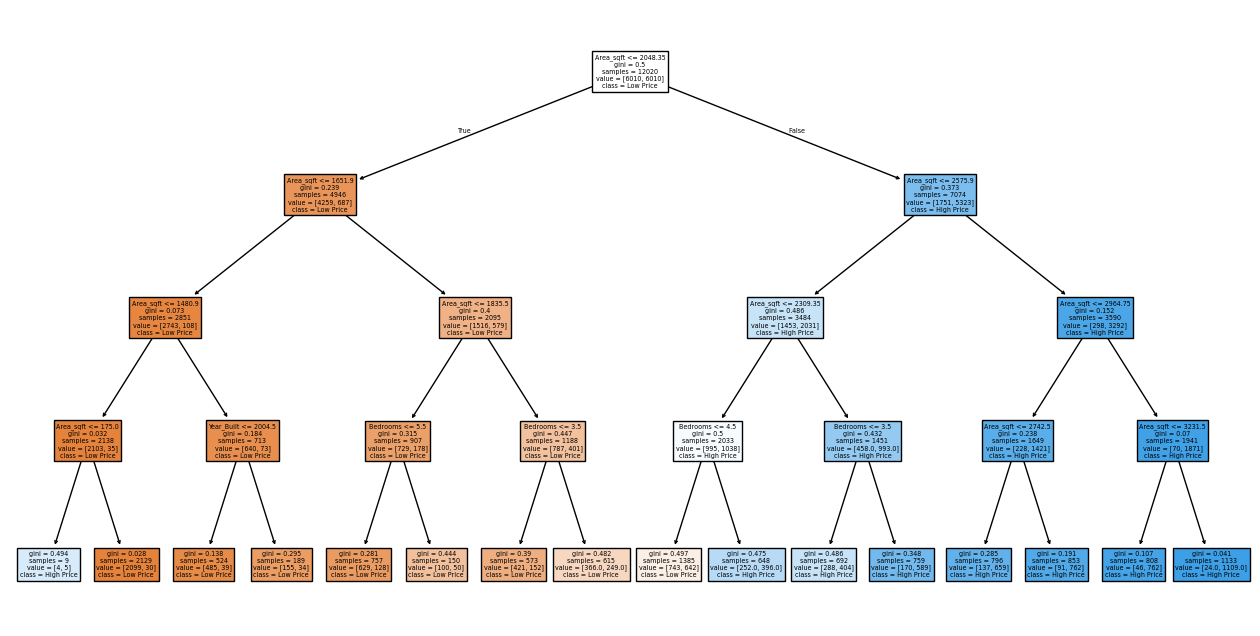

In [8]:
tree_model = model.named_steps['decisiontreeclassifier']

plt.figure(figsize=(16, 8))

plot_tree(
    tree_model,
    feature_names=X.columns,
    class_names=['Low Price', 'High Price'],
    filled=True
)

plt.show()